# ML Experiment Results

Generic template notebook: loads every experiment JSON for one greenhouse +
target combination, builds summary tables and plots.

To create one of the four target notebooks (Alava/temperature,
Alava/rel_humidity, Cartagena/temperature, Cartagena/rel_humidity), copy
this notebook and only change `GREENHOUSE` and `TARGET` in the Config cell
below — everything else adapts automatically.


In [30]:
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams["figure.dpi"] = 110


## 1. Configuration

In [ ]:
# Greenhouse and target this notebook analyzes.
# GREENHOUSE: "alava" or "cartagena"
# TARGET:     "temperature" or "rel_humidity"
GREENHOUSE = "alava"
TARGET = "temperature"

# Base results folder for this greenhouse (one subfolder per model:
# lstm/, gru/, cnn_lstm/, dlinear/, nlinear/, patchtst/, itransformer/).
RESULTS_DIR = Path(f"../results/experiments/{GREENHOUSE}")

# Glob pattern: picks up every model's JSON for the chosen target, e.g.
# results/experiments/alava/lstm/temperature/01_lstm_alava_temp.json
PATTERN = f"*/{TARGET}/*.json"


## 2. Load data

In [32]:
def experiment_name(path: Path) -> str:
    """Experiment name derived from the file name.

    By default uses the file name as-is (without extension). If your
    files include a repetition/seed suffix you want to ignore when
    grouping (e.g. 'my_experiment_seed3.json'), adjust the regex here,
    for example:
        return re.sub(r"_seed\d+$", "", path.stem)
    """
    return path.stem


def load_results(directory: Path, pattern: str = "*.json"):
    """Loads every result JSON into a list of dicts, adding file/experiment
    metadata.

    Supports two file formats:
    - A single results dict per file: {..., "metrics": {...}}
    - A list of results dicts per file: [{...}, {...}, ...]
      (each list element is treated as a distinct repetition/run of the
      same file, and numbered automatically). This is the normal case
      here: each experiment script appends one entry per run to its JSON,
      so a script run 3 times produces a 3-element list.
    """
    files = sorted(Path(directory).glob(pattern))
    if not files:
        raise FileNotFoundError(f"No '{pattern}' files found in {directory}")

    data = []
    for f in files:
        with open(f, "r", encoding="utf-8") as fh:
            content = json.load(fh)

        # Normalize to a list of dicts, however the file is shaped
        if isinstance(content, dict):
            items = [content]
        elif isinstance(content, list):
            items = content
        else:
            raise ValueError(f"Unexpected format in {f.name}: expected dict or list, "
                              f"got {type(content)}")

        for i, d in enumerate(items):
            if not isinstance(d, dict):
                raise ValueError(f"Item {i} of {f.name} is not a dict (it's {type(d)})")
            d = dict(d)  # copy so we don't mutate the original
            d["_file"] = f.name if len(items) == 1 else f"{f.name}[{i}]"
            d["_experiment"] = experiment_name(f)
            data.append(d)
    return data


results = load_results(RESULTS_DIR, PATTERN)
print(f"Loaded {len(results)} result files, "
      f"corresponding to {len(set(d['_experiment'] for d in results))} distinct experiment(s).")


Loaded 33 result files, corresponding to 7 distinct experiment(s).


<>:8: SyntaxWarning: invalid escape sequence '\d'
<>:8: SyntaxWarning: invalid escape sequence '\d'
C:\Users\jclps\AppData\Local\Temp\ipykernel_22652\1520848580.py:8: SyntaxWarning: invalid escape sequence '\d'
  return re.sub(r"_seed\d+$", "", path.stem)


## 3. Building the DataFrames

In [33]:
def build_global_df(data):
    rows = []
    for d in data:
        row = {"experiment": d["_experiment"], "file": d["_file"]}
        row.update(d["metrics"]["global"])
        rows.append(row)
    return pd.DataFrame(rows)


def build_horizon_df(data):
    rows = []
    for d in data:
        for h_key, metrics in d["metrics"]["per_horizon"].items():
            row = {
                "experiment": d["_experiment"],
                "file": d["_file"],
                "horizon": int(h_key.split("_")[1]),
            }
            row.update(metrics)
            rows.append(row)
    return pd.DataFrame(rows)


def build_month_df(data):
    rows = []
    for d in data:
        for month, metrics in d["metrics"].get("per_month", {}).items():
            row = {"experiment": d["_experiment"], "file": d["_file"], "month": month}
            row.update(metrics)
            rows.append(row)
    return pd.DataFrame(rows)


def build_day_night_df(data):
    rows = []
    for d in data:
        for period in ("day", "night"):
            metrics = d["metrics"].get(period)
            if metrics:
                row = {"experiment": d["_experiment"], "file": d["_file"], "period": period}
                row.update(metrics)
                rows.append(row)
    return pd.DataFrame(rows)


df_global = build_global_df(results)
df_horizon = build_horizon_df(results)
df_month = build_month_df(results)
df_day_night = build_day_night_df(results)

df_global.head()


,experiment,file,r2,mse,rmse,mae,mape,relative_error,relative_error_abs
0,05_cnn_lstm_alava_temp,05_cnn_lstm_alava_temp.json[0],0.774,11.566,3.401,2.178,10.759,0.030,0.108
1,05_cnn_lstm_alava_temp,05_cnn_lstm_alava_temp.json[1],0.770,11.768,3.430,2.173,10.594,0.032,0.106
2,05_cnn_lstm_alava_temp,05_cnn_lstm_alava_temp.json[2],0.782,11.163,3.341,2.095,10.276,0.026,0.103
3,05_cnn_lstm_alava_temp,05_cnn_lstm_alava_temp.json[3],0.797,10.405,3.226,2.095,10.452,0.033,0.105
4,05_cnn_lstm_alava_temp,05_cnn_lstm_alava_temp.json[4],0.767,11.924,3.453,2.162,10.618,0.030,0.106


## 4. Global metrics table (mean ± std per experiment)

In [34]:
GLOBAL_METRICS = ["r2", "mse", "rmse", "mae", "mape"]  #, "relative_error", "relative_error_abs"]

global_table = (
    df_global
    .groupby("experiment")[GLOBAL_METRICS]
    .agg(["mean", "std"])
    .round(4)
)

# Flatten the multi-index columns, e.g. ('r2', 'mean') -> 'r2_mean'
global_table.columns = [f"{metric}_{stat}" for metric, stat in global_table.columns]
global_table = global_table.sort_index()
global_table


,r2_mean,r2_std,mse_mean,mse_std,rmse_mean,rmse_std,mae_mean,mae_std,mape_mean,mape_std
experiment,,,,,,,,,,
01_lstm_alava_temp,0.787,0.011,10.896,0.579,3.300,0.088,2.109,0.017,10.354,0.069
03_gru_alava_temp,0.805,0.008,9.980,0.394,3.159,0.063,2.039,0.046,10.145,0.280
05_cnn_lstm_alava_temp,0.778,0.012,11.365,0.608,3.370,0.091,2.141,0.042,10.540,0.183
07_dlinear_alava,0.858,0.001,7.284,0.034,2.699,0.006,1.816,0.004,9.399,0.084
08_nlinear_alava,0.859,0.001,7.232,0.069,2.689,0.013,1.781,0.012,9.171,0.082
09_patchtst_alava,0.870,0.004,6.702,0.192,2.589,0.037,1.773,0.025,8.972,0.119
10_itransformer_alava,0.889,0.003,5.682,0.165,2.384,0.035,1.578,0.029,7.804,0.154


### Compact 'mean ± std' version, easier to read

In [35]:
def mean_std_table(df, metrics, group_cols):
    agg = df.groupby(group_cols)[metrics].agg(["mean", "std"])
    out = pd.DataFrame(index=agg.index)
    for m in metrics:
        mean = agg[(m, "mean")]
        std = agg[(m, "std")].fillna(0)
        out[m] = [f"{mu:.3f} \u00b1 {sd:.3f}" for mu, sd in zip(mean, std)]
    return out.sort_index()


compact_global_table = mean_std_table(df_global, GLOBAL_METRICS, ["experiment"])
compact_global_table


,r2,mse,rmse,mae,mape
experiment,,,,,
01_lstm_alava_temp,0.787 ± 0.011,10.896 ± 0.579,3.300 ± 0.088,2.109 ± 0.017,10.354 ± 0.069
03_gru_alava_temp,0.805 ± 0.008,9.981 ± 0.394,3.159 ± 0.063,2.039 ± 0.046,10.145 ± 0.280
05_cnn_lstm_alava_temp,0.778 ± 0.012,11.365 ± 0.608,3.370 ± 0.091,2.141 ± 0.042,10.540 ± 0.183
07_dlinear_alava,0.858 ± 0.001,7.284 ± 0.034,2.699 ± 0.006,1.816 ± 0.004,9.399 ± 0.084
08_nlinear_alava,0.859 ± 0.001,7.232 ± 0.069,2.689 ± 0.013,1.781 ± 0.012,9.172 ± 0.082
09_patchtst_alava,0.870 ± 0.004,6.702 ± 0.192,2.589 ± 0.037,1.773 ± 0.025,8.972 ± 0.119
10_itransformer_alava,0.889 ± 0.003,5.682 ± 0.164,2.384 ± 0.035,1.578 ± 0.028,7.804 ± 0.154


In [36]:
compact_global_table.to_latex()


'\\begin{tabular}{llllll}\n\\toprule\n & r2 & mse & rmse & mae & mape \\\\\nexperiment &  &  &  &  &  \\\\\n\\midrule\n01_lstm_alava_temp & 0.787 ± 0.011 & 10.896 ± 0.579 & 3.300 ± 0.088 & 2.109 ± 0.017 & 10.354 ± 0.069 \\\\\n03_gru_alava_temp & 0.805 ± 0.008 & 9.981 ± 0.394 & 3.159 ± 0.063 & 2.039 ± 0.046 & 10.145 ± 0.280 \\\\\n05_cnn_lstm_alava_temp & 0.778 ± 0.012 & 11.365 ± 0.608 & 3.370 ± 0.091 & 2.141 ± 0.042 & 10.540 ± 0.183 \\\\\n07_dlinear_alava & 0.858 ± 0.001 & 7.284 ± 0.034 & 2.699 ± 0.006 & 1.816 ± 0.004 & 9.399 ± 0.084 \\\\\n08_nlinear_alava & 0.859 ± 0.001 & 7.232 ± 0.069 & 2.689 ± 0.013 & 1.781 ± 0.012 & 9.172 ± 0.082 \\\\\n09_patchtst_alava & 0.870 ± 0.004 & 6.702 ± 0.192 & 2.589 ± 0.037 & 1.773 ± 0.025 & 8.972 ± 0.119 \\\\\n10_itransformer_alava & 0.889 ± 0.003 & 5.682 ± 0.164 & 2.384 ± 0.035 & 1.578 ± 0.028 & 7.804 ± 0.154 \\\\\n\\bottomrule\n\\end{tabular}\n'

## 5. Metrics table by month and by day/night

In [37]:
MONTH_METRICS = ["r2", "mse", "rmse", "mae", "mape"]

month_table = mean_std_table(df_month, MONTH_METRICS, ["experiment", "month"])
month_table


r2             mse           rmse  \
experiment            month                                                   
01_lstm_alava_temp    2025-06  0.750 ± 0.023   7.433 ± 0.682  2.724 ± 0.126   
                      2025-07  0.720 ± 0.008   8.227 ± 0.244  2.868 ± 0.042   
                      2025-08  0.597 ± 0.054  45.007 ± 6.039  6.697 ± 0.449   
                      2025-09  0.625 ± 0.020   7.570 ± 0.404  2.751 ± 0.073   
                      2025-10  0.645 ± 0.008   7.430 ± 0.172  2.726 ± 0.031   
...                                      ...             ...            ...   
10_itransformer_alava 2025-10  0.881 ± 0.004   2.481 ± 0.092  1.575 ± 0.029   
                      2025-11  0.702 ± 0.006   4.413 ± 0.085  2.101 ± 0.020   
                      2025-12  0.549 ± 0.009   5.339 ± 0.106  2.311 ± 0.023   
                      2026-01  0.522 ± 0.032   6.926 ± 0.463  2.631 ± 0.087   
                      2026-02  0.694 ± 0.006   8.277 ± 0.165  2.877 ± 0.029   

                                         mae            mape  
experiment            month                                   
01_lstm_alava_temp    2025-06  1.808 ± 0.060   7.090 ± 0.166  
                      2025-07  1.834 ± 0.042   7.433 ± 0.199  
                      2025-08  4.219 ± 0.312  11.155 ± 0.838  
                      2025-09  2.014 ± 0.091  10.117 ± 0.374  
                      2025-10  1.837 ± 0.032   9.101 ± 0.146  
...                                      ...             ...  
10_itransformer_alava 2025-10  1.114 ± 0.018   5.363 ± 0.117  
                      2025-11  1.509 ± 0.010   8.256 ± 0.043  
                      2025-12  1.576 ± 0.026   9.177 ± 0.200  
                      2026-01  1.813 ± 0.043  11.280 ± 0.273  
                      2026-02  2.007 ± 0.038  12.877 ± 0.391  

[63 rows x 5 columns]

In [38]:
DAY_NIGHT_METRICS = ["r2", "mse", "rmse", "mae", "mape", "relative_error", "relative_error_abs"]

day_night_table = mean_std_table(df_day_night, DAY_NIGHT_METRICS, ["experiment", "period"])
day_night_table


r2             mse           rmse  \
experiment             period                                                 
01_lstm_alava_temp     day     0.733 ± 0.019  17.316 ± 1.214  4.159 ± 0.146   
                       night   0.772 ± 0.004   4.797 ± 0.092  2.190 ± 0.021   
03_gru_alava_temp      day     0.761 ± 0.009  15.508 ± 0.555  3.938 ± 0.071   
                       night   0.776 ± 0.017   4.729 ± 0.355  2.173 ± 0.082   
05_cnn_lstm_alava_temp day     0.722 ± 0.017  18.007 ± 1.118  4.242 ± 0.133   
                       night   0.760 ± 0.019   5.055 ± 0.400  2.247 ± 0.088   
07_dlinear_alava       day     0.835 ± 0.002  10.761 ± 0.116  3.280 ± 0.018   
                       night   0.811 ± 0.002   3.992 ± 0.052  1.998 ± 0.013   
08_nlinear_alava       day     0.835 ± 0.001  10.745 ± 0.082  3.278 ± 0.012   
                       night   0.815 ± 0.003   3.906 ± 0.068  1.976 ± 0.017   
09_patchtst_alava      day     0.845 ± 0.004  10.189 ± 0.286  3.192 ± 0.045   
                       night   0.839 ± 0.006   3.417 ± 0.122  1.848 ± 0.033   
10_itransformer_alava  day     0.862 ± 0.004   9.009 ± 0.257  3.001 ± 0.043   
                       night   0.880 ± 0.005   2.532 ± 0.112  1.591 ± 0.035   

                                         mae            mape  relative_error  \
experiment             period                                                  
01_lstm_alava_temp     day     2.695 ± 0.040  10.953 ± 0.105  -0.015 ± 0.008   
                       night   1.553 ± 0.020   9.785 ± 0.126   0.067 ± 0.004   
03_gru_alava_temp      day     2.561 ± 0.027  10.533 ± 0.116  -0.009 ± 0.005   
                       night   1.544 ± 0.072   9.777 ± 0.458   0.064 ± 0.005   
05_cnn_lstm_alava_temp day     2.725 ± 0.049  11.106 ± 0.157  -0.012 ± 0.002   
                       night   1.586 ± 0.052  10.002 ± 0.281   0.071 ± 0.004   
07_dlinear_alava       day     2.296 ± 0.015  10.325 ± 0.017   0.005 ± 0.006   
                       night   1.362 ± 0.015   8.522 ± 0.148   0.032 ± 0.007   
08_nlinear_alava       day     2.266 ± 0.019  10.237 ± 0.106   0.007 ± 0.003   
                       night   1.321 ± 0.009   8.163 ± 0.065   0.022 ± 0.003   
09_patchtst_alava      day     2.260 ± 0.033  10.034 ± 0.138   0.008 ± 0.006   
                       night   1.315 ± 0.024   7.972 ± 0.148   0.023 ± 0.006   
10_itransformer_alava  day     2.088 ± 0.030   9.010 ± 0.153  -0.006 ± 0.005   
                       night   1.095 ± 0.028   6.662 ± 0.158   0.009 ± 0.004   

                              relative_error_abs  
experiment             period                     
01_lstm_alava_temp     day         0.110 ± 0.001  
                       night       0.098 ± 0.001  
03_gru_alava_temp      day         0.105 ± 0.001  
                       night       0.098 ± 0.005  
05_cnn_lstm_alava_temp day         0.111 ± 0.002  
                       night       0.100 ± 0.003  
07_dlinear_alava       day         0.103 ± 0.000  
                       night       0.085 ± 0.001  
08_nlinear_alava       day         0.102 ± 0.001  
                       night       0.082 ± 0.001  
09_patchtst_alava      day         0.100 ± 0.001  
                       night       0.080 ± 0.001  
10_itransformer_alava  day         0.090 ± 0.002  
                       night       0.067 ± 0.002

## 6. Metric evolution across the prediction horizon

`plot_metric_by_horizon` plots a single metric for one or more experiments.
If an experiment has several repetitions (same `experiment`, different
files), the mean is drawn together with a shaded band of ± 1 standard
deviation.

The following cell (`plot_all_metrics_by_horizon`) reuses the same logic to
draw **every metric at once**, as a grid of subplots, so a single cell
produces the full picture instead of one plot per cell.


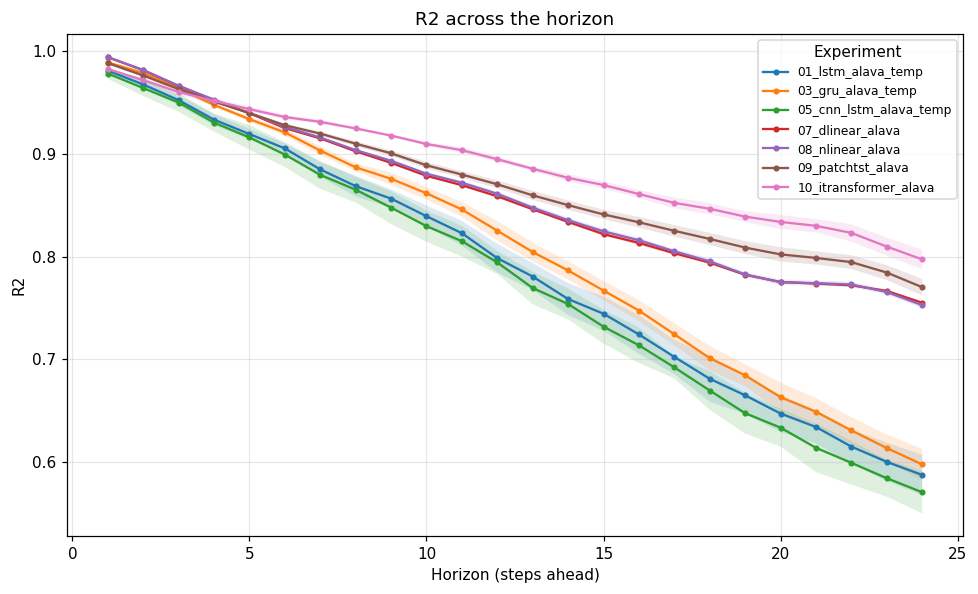

In [39]:
def plot_metric_by_horizon(df_horizon, experiments=None, metric="r2", ax=None,
                            figsize=(9, 5.5), title=None):
    """Plots the evolution of one metric (default r2) across the prediction
    horizon, for one or more experiments.

    Parameters
    ----------
    df_horizon : DataFrame returned by build_horizon_df
    experiments : str, list of str, or None (None = every available experiment)
    metric : metric column name to plot ('r2', 'mae', 'rmse', 'mape', ...)
    """
    if experiments is None:
        experiments = sorted(df_horizon["experiment"].unique())
    elif isinstance(experiments, str):
        experiments = [experiments]

    owns_figure = ax is None
    if owns_figure:
        fig, ax = plt.subplots(figsize=figsize)

    for experiment in experiments:
        subset = df_horizon[df_horizon["experiment"] == experiment]
        agg = subset.groupby("horizon")[metric].agg(["mean", "std"]).sort_index()
        ax.plot(agg.index, agg["mean"], marker="o", markersize=3, label=experiment)
        std = agg["std"].fillna(0)
        if (std > 0).any():
            ax.fill_between(agg.index, agg["mean"] - std, agg["mean"] + std, alpha=0.15)

    ax.set_xlabel("Horizon (steps ahead)")
    ax.set_ylabel(metric.upper() if metric in ("r2", "mae", "mse", "rmse") else metric)
    ax.set_title(title or f"{metric.upper()} across the horizon")
    ax.grid(alpha=0.3)
    ax.legend(title="Experiment", fontsize=8)
    if owns_figure:
        plt.tight_layout()
    return ax


plot_metric_by_horizon(df_horizon)
plt.show()


### All metrics at once

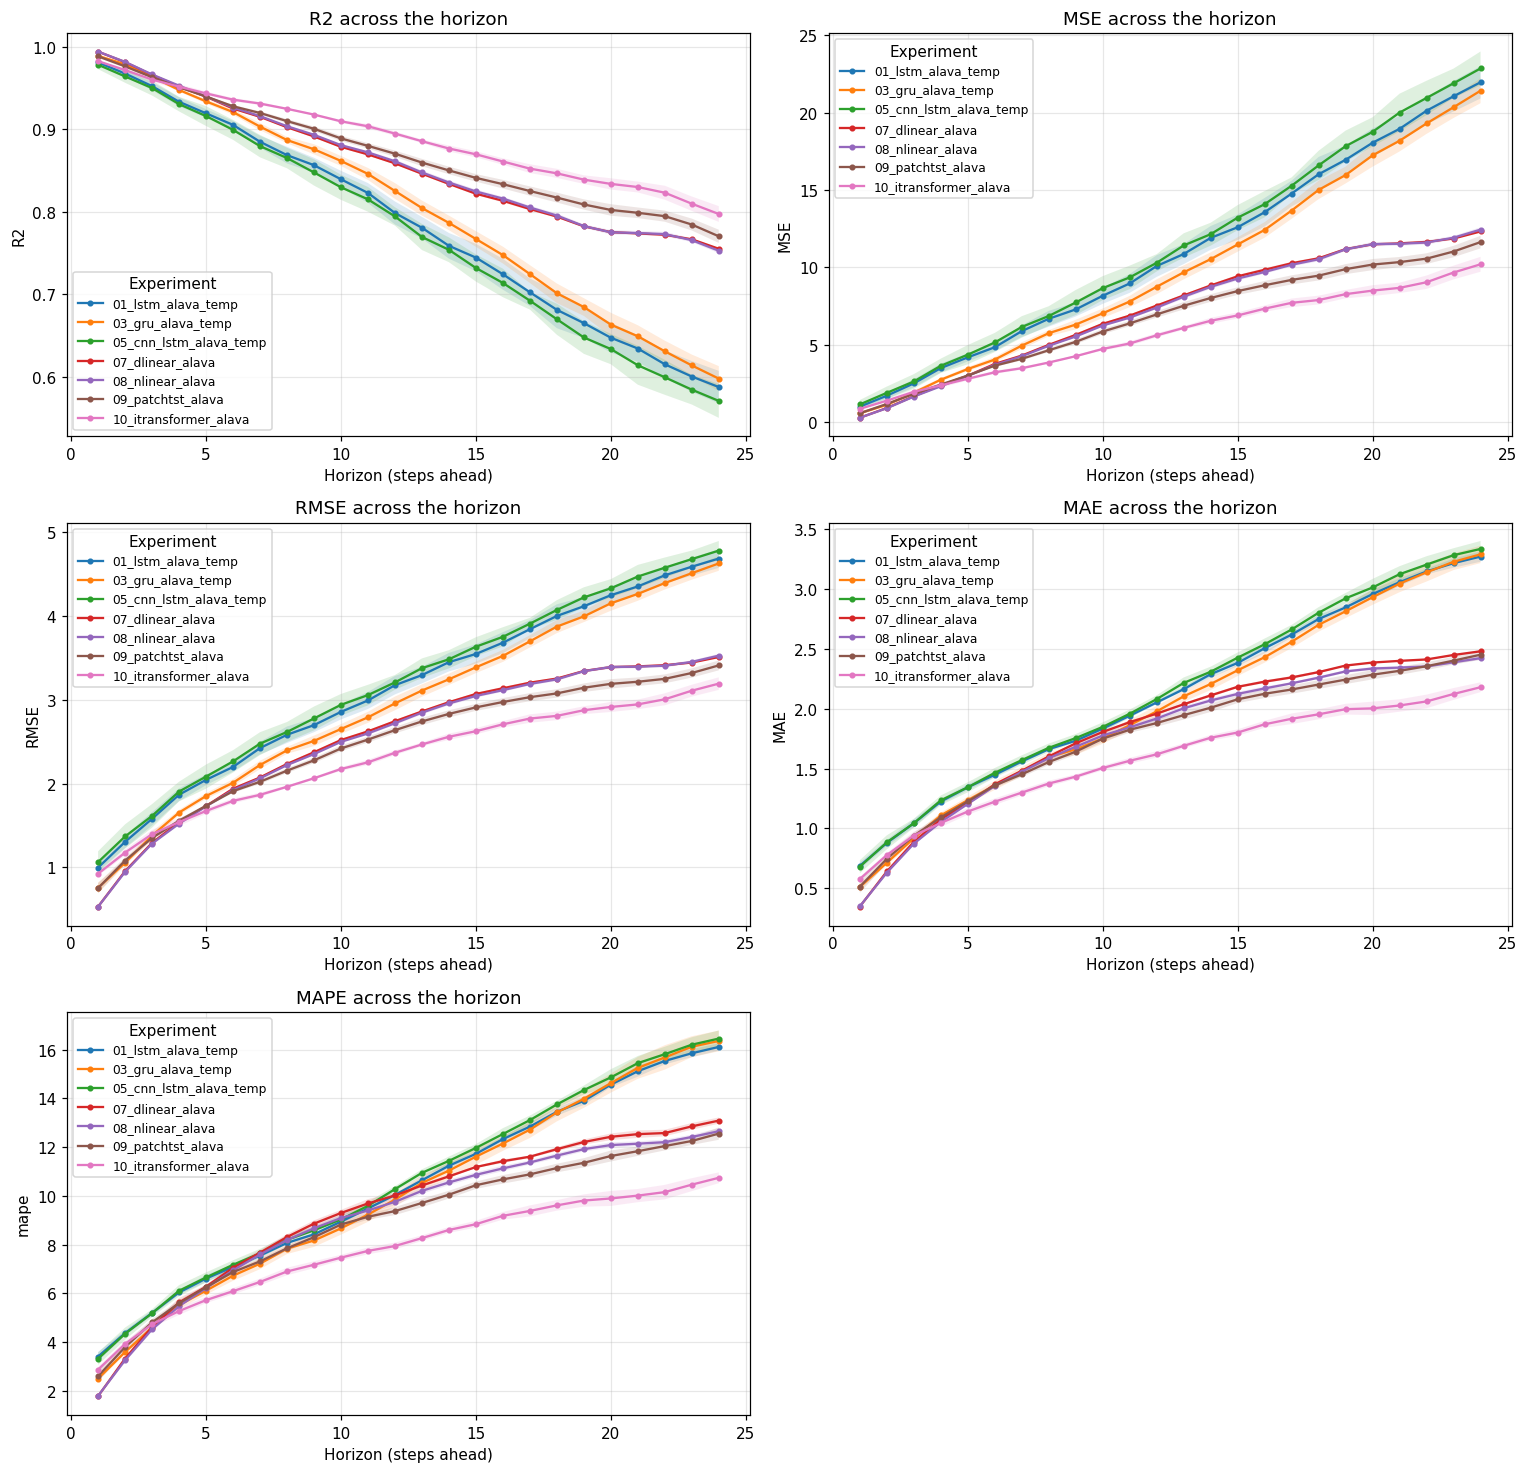

In [40]:
def plot_all_metrics_by_horizon(df_horizon, experiments=None,
                                 metrics=GLOBAL_METRICS, ncols=2, figsize=(7, 4.5)):
    """Draws one subplot per metric (all of GLOBAL_METRICS by default), each
    showing every experiment, in a single figure - the one-cell replacement
    for calling plot_metric_by_horizon once per metric.
    """
    nrows = -(-len(metrics) // ncols)  # ceil division
    fig, axes = plt.subplots(nrows, ncols, figsize=(figsize[0] * ncols, figsize[1] * nrows))
    axes = np.array(axes).reshape(-1)

    for ax, metric in zip(axes, metrics):
        plot_metric_by_horizon(df_horizon, experiments=experiments, metric=metric, ax=ax)

    # Hide unused axes if metrics don't fill the grid exactly
    for ax in axes[len(metrics):]:
        ax.set_visible(False)

    fig.tight_layout()
    return fig


plot_all_metrics_by_horizon(df_horizon)
plt.show()
